# 05. DBSCAN: memilih eps dan membaca hasil

Ikuti tiga langkah utama seperti saat membaca grafik K-Means: lihat kurva jarak, bandingkan kandidat parameter, lalu baca hasil kelompok. Data yang dipakai tetap training 2021-2025; lokasi tidak menjadi fitur kemiripan.

**Baca tiga grafik utama secara berurutan:** [1. Kurva k-distance](#s7) → [2. Grafik eps dan skor](#s8) → [3. Hasil kelompok](#s9). [Nama kelompok](#s6) | [Lampiran teknis](#s10). Grafik langsung tampil di bawah sel kode.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../04_kmeans/04_kmeans.ipynb) | [Berikutnya](../06_model_evaluation/06_model_evaluation.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Kode perhitungan kelompok dan skor](#s2)
- [3. Kode pencarian parameter DBSCAN](#s3)
- [4. Jalankan atau baca hasil DBSCAN](#s4)
- [5. Penamaan dan interpretasi kelompok (setelah clustering)](#s5)
- [6. Tabel nama kelompok dan angka dasarnya](#s6)
- [7. Langkah 1: lihat kurva k-distance](#s7)
- [8. Langkah 2: bandingkan eps dengan grafik skor](#s8)
- [9. Langkah 3: baca hasil kelompok dan noise](#s9)
- [10. Lampiran: seluruh percobaan dan rincian skor](#s10)
- [11. Ringkasan alur DBSCAN](#s11)

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_prepared, save_model_metadata

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Kode perhitungan kelompok dan skor

Kode berikut mendukung proses pengelompokan. Untuk membaca hasil, mulai bagian 4 lalu ikuti grafik bagian 7-9. Satu baris data adalah satu kotak selama tiga bulan.

In [2]:
def cluster_metrics(X, labels, sample_size=2000, seed=42):
    X, labels = np.asarray(X), np.asarray(labels)
    assigned = labels >= 0
    values, counts = np.unique(labels[assigned], return_counts=True)
    result = {"n_rows": len(labels), "n_clusters": len(values), "n_assigned": int(assigned.sum()),
              "noise_fraction": float((~assigned).mean()),
              "largest_cluster_fraction_assigned": float(counts.max()/counts.sum()) if len(counts) else np.nan,
              "smallest_cluster_size": int(counts.min()) if len(counts) else 0,
              "silhouette": np.nan, "davies_bouldin": np.nan, "silhouette_n": 0}
    if len(values) < 2 or assigned.sum() <= len(values):
        return result
    xx, yy = X[assigned], labels[assigned]
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(xx), min(sample_size, len(xx)), replace=False)
    observed = len(np.unique(yy[indices]))
    if 1 < observed < len(indices):
        result["silhouette"] = float(silhouette_score(xx[indices], yy[indices]))
        result["silhouette_n"] = len(indices)
    result["davies_bouldin"] = float(davies_bouldin_score(xx, yy))
    return result

def full_labels(panel, train, labels, method):
    values = train[["row_id"]].copy()
    values["cluster"] = labels
    result = panel.loc[panel["split"].eq("train")].merge(values, on="row_id", how="left", validate="one_to_one")
    result["profile"] = result["state"]
    valid = result["cluster"].notna()
    result.loc[valid, "profile"] = result.loc[valid, "cluster"].astype(int).map(
        lambda n: "NOISE" if n < 0 else f"{method.upper()}_P{n}")
    return result

def profile_table(result, features):
    eligible = result.loc[result["cluster"].notna()]
    table = eligible.groupby("profile")[features + ["earthquake_count", "frequency_per_month", "depth_coverage"]].mean()
    table["n_grid_quarters"] = eligible.groupby("profile").size()
    table["low_support_fraction"] = eligible.groupby("profile")["low_support"].mean()
    return table.reset_index()

def save_cluster_plot(root, method, X, labels):
    projection = PCA(n_components=2, random_state=42).fit_transform(X)
    fig, ax = plt.subplots(figsize=(9, 6))
    for label in sorted(np.unique(labels)):
        mask = labels == label
        ax.scatter(projection[mask, 0], projection[mask, 1], s=7, alpha=.45,
                   label=("Noise" if label < 0 else f"Profil {label}") if len(np.unique(labels)) <= 20 else None)
    ax.set(xlabel="PC1", ylabel="PC2", title=f"{method.upper()}: proyeksi PCA fitur training (bukan koordinat)")
    if len(np.unique(labels)) <= 20:
        ax.legend()
    fig.tight_layout()
    fig.savefig(Path(root) / f"reports/figures/{method}_pca.png", dpi=160)
    plt.close(fig)

<a id="s3"></a>
## 3. Kode pencarian parameter DBSCAN

DBSCAN mencoba eps dan min_samples, kemudian menghasilkan jumlah kelompok. Seluruh percobaan disimpan. Penjelasan grafik ada di bagian 7-9; aturan pemeriksaan lengkap tersedia di bagian 10.

In [3]:
def fit_dbscan(root=ROOT):
    root = Path(root)
    cfg, panel, train, X, _, meta = load_prepared(root)
    rows = []
    fig, ax = plt.subplots(figsize=(9, 5))
    with threadpool_limits(limits=2):
        for min_samples in cfg["dbscan_min_samples"]:
            if min_samples > len(X):
                continue
            # Query X secara eksplisit: tetangga diri berjarak nol ikut dihitung seperti min_samples DBSCAN.
            distances = NearestNeighbors(n_neighbors=min_samples, n_jobs=1).fit(X).kneighbors(X)[0][:, -1]
            ax.plot(np.sort(distances), label=f"min_samples={min_samples}")
            candidates = sorted(set(float(v) for v in np.quantile(distances, cfg["dbscan_distance_quantiles"]) if v > 0))
            if not candidates:
                candidates = [0.05, 0.1, 0.2]
            for eps in candidates:
                labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=1).fit_predict(X)
                metrics = cluster_metrics(X, labels, cfg["silhouette_sample_size"])
                repeat_scores = [cluster_metrics(X, labels, cfg["silhouette_sample_size"], seed)["silhouette"] for seed in cfg["silhouette_seeds"]]
                metrics["silhouette"] = float(np.nanmean(repeat_scores)) if np.isfinite(repeat_scores).any() else np.nan
                metrics["silhouette_std"] = float(np.nanstd(repeat_scores)) if np.isfinite(repeat_scores).any() else np.nan
                accepted = (metrics["n_clusters"] >= 2 and np.isfinite(metrics["silhouette"])
                            and metrics["n_clusters"] <= cfg["dbscan_max_clusters"]
                            and metrics["smallest_cluster_size"] >= cfg["dbscan_min_cluster_size"]
                            and metrics["noise_fraction"] <= cfg["dbscan_max_noise_fraction"]
                            and metrics["largest_cluster_fraction_assigned"] <= cfg["dbscan_max_largest_cluster_fraction"])
                rows.append({"eps": eps, "min_samples": min_samples, "accepted": accepted, **metrics})
        scores = pd.DataFrame(rows)
        if scores.empty:
            raise ValueError("Tidak ada kandidat DBSCAN.")
        pool = scores.loc[scores["accepted"]]
        diagnostic_only = pool.empty
        if diagnostic_only:
            pool = scores
        selected = pool.sort_values(["silhouette", "noise_fraction"], ascending=[False, True], na_position="last").iloc[0]
        model = DBSCAN(eps=float(selected["eps"]), min_samples=int(selected["min_samples"]), n_jobs=1).fit(X)
    result = full_labels(panel, train, model.labels_, "dbscan")
    directory = root / "models/dbscan"
    scores.to_csv(directory / "parameter_search.csv", index=False)
    result.to_csv(directory / "training_labels.csv", index=False)
    profile_table(result, cfg["features"]).to_csv(directory / "profiles.csv", index=False)
    joblib.dump(model, directory / "model.joblib")
    save_model_metadata(root, "dbscan", meta, {"eps": float(selected["eps"]), "min_samples": int(selected["min_samples"]),
                        "diagnostic_only": diagnostic_only, "fit_split": "train",
                        "selection": "rata-rata silhouette tertinggi di kandidat lolos batas noise, dominasi, fragmentasi dan dukungan; jika tidak ada, hanya diagnostik"})
    ax.set(title="k-distance training: dasar kandidat eps", xlabel="Observasi diurutkan", ylabel="Jarak ke tetangga ke-k")
    ax.legend()
    fig.tight_layout()
    fig.savefig(root / "reports/figures/dbscan_k_distance.png", dpi=160)
    plt.close(fig)
    save_cluster_plot(root, "dbscan", X, model.labels_)
    if diagnostic_only:
        print("Tidak ada kandidat DBSCAN lolos kriteria. Hasil disimpan untuk diagnosis, bukan model yang telah tervalidasi.")
    return scores, result

<a id="s4"></a>
## 4. Jalankan atau baca hasil DBSCAN

Jika hasil tersimpan tersedia dan sesuai dengan preprocessing, gunakan hasil tersebut. Ubah LATIH_ULANG = True untuk mengulang seluruh pencarian; jika hasil belum ada, pelatihan dijalankan otomatis. Data atau konfigurasi yang berubah harus diproses ulang sesuai urutan notebook.

In [4]:
from src.common import load_model

LATIH_ULANG = False
saved_files = [ROOT / f"models/dbscan/{name}" for name in ["model.joblib", "metadata.json", "parameter_search.csv", "training_labels.csv"]]
if LATIH_ULANG or not all(path.is_file() for path in saved_files):
    search, labels = fit_dbscan(ROOT)
    print("Pencarian parameter dan pelatihan DBSCAN selesai.")
else:
    search = pd.read_csv(ROOT / "models/dbscan/parameter_search.csv")
    labels = pd.read_csv(ROOT / "models/dbscan/training_labels.csv")
    print("Membaca hasil training tersimpan. Ubah LATIH_ULANG menjadi True untuk mengulang pencarian.")

evaluation_cfg, evaluation_panel, evaluation_train, evaluation_X, _, _ = load_prepared(ROOT)
dbscan_model, dbscan_metadata = load_model(ROOT, "dbscan")
candidate_results = search.copy()
selected_mask = (np.isclose(search["eps"], dbscan_metadata["eps"], rtol=1e-10, atol=1e-12)
                 & search["min_samples"].eq(dbscan_metadata["min_samples"]))
assert selected_mask.sum() == 1
selected_result = search.loc[selected_mask].iloc[0]
assert len(dbscan_model.labels_) == len(evaluation_X)
final_metrics = cluster_metrics(evaluation_X, dbscan_model.labels_, cfg["silhouette_sample_size"], seed=42)
assert final_metrics["n_assigned"] == selected_result["n_assigned"]
assert final_metrics["n_clusters"] == selected_result["n_clusters"]
angka = lambda value, digits=4: f"{value:.{digits}f}".replace(".", ",")
jumlah = lambda value: f"{int(value):,}".replace(",", ".")
noise_rows = final_metrics["n_rows"] - final_metrics["n_assigned"]
display(Markdown(f"""### Ikuti tiga langkah grafik

1. **Bagian 7:** lihat kurva k-distance untuk memahami jarak antarpola.
2. **Bagian 8:** bandingkan nilai eps dan skor, seperti grafik pilihan k pada K-Means.
3. **Bagian 9:** baca jumlah kelompok, noise, dan ringkasan hasilnya.

**Hasil tersimpan:** eps **{angka(dbscan_metadata['eps'], 3)}**, min_samples **{dbscan_metadata['min_samples']}**.
Model memakai **{jumlah(len(evaluation_train))} baris kotak-triwulan 2021-2025**, tanpa data testing 2026.
"""))


Membaca hasil training tersimpan. Ubah LATIH_ULANG menjadi True untuk mengulang pencarian.


### Ikuti tiga langkah grafik

1. **Bagian 7:** lihat kurva k-distance untuk memahami jarak antarpola.
2. **Bagian 8:** bandingkan nilai eps dan skor, seperti grafik pilihan k pada K-Means.
3. **Bagian 9:** baca jumlah kelompok, noise, dan ringkasan hasilnya.

**Hasil tersimpan:** eps **0,505**, min_samples **20**.
Model memakai **13.471 baris kotak-triwulan 2021-2025**, tanpa data testing 2026.


<a id="s5"></a>
## 5. Penamaan dan interpretasi kelompok (setelah clustering)

DBSCAN sudah membentuk kelompok pada bagian sebelumnya. Di sini kita membaca cirinya lalu memberi nama deskriptif. Nama tidak menentukan anggota kelompok atau mengubah noise. Aturan nama sama dengan K-Means, tetapi Kelompok A DBSCAN tidak sama dengan Kelompok A K-Means. Statistik pembentuk nama hanya memakai training 2021-2025; tidak memakai testing 2026.

In [5]:
from src.mapping import profile_color

def profile_descriptions(root, method, cfg):
    profiles = pd.read_csv(Path(root) / f"models/{method}/profiles.csv")
    clusters = profiles.loc[profiles["profile"].str.contains("_P", regex=False)].copy()
    maximum_count = clusters["earthquake_count"].max()
    descriptions = {}
    for row in clusters.itertuples():
        number = int(row.profile.rsplit("_P", 1)[1])
        group = f"Kelompok {chr(65 + number)}"
        magnitude = f"{row.avg_magnitude:.1f}".replace(".", ",")
        count = f"{row.earthquake_count:.1f}".replace(".", ",")
        depth = f"{row.avg_depth:.0f}"
        if row.avg_depth < cfg["shallow_depth_km"]:
            characteristic = f"Cenderung dangkal, magnitudo sekitar {magnitude}"
        else:
            characteristic = f"Kedalaman sekitar {depth} km, magnitudo {magnitude}"
        if row.earthquake_count == maximum_count:
            characteristic = "Kejadian lebih sering; " + ("cenderung dangkal" if row.avg_depth < cfg["shallow_depth_km"] else f"kedalaman sekitar {depth} km")
        descriptions[row.profile] = {
            "name": group + ": " + characteristic,
            "detail": f"Rata-rata {count} kejadian / 3 bulan; magnitudo {magnitude}; kedalaman {depth} km.",
            "source": "Ringkasan statistik cluster historis 2021-2025, bukan kategori yang menentukan anggota cluster.",
            "color": profile_color(row.profile),
        }
    special_names = {
        "NO_EVENTS": f"Tidak ada gempa tercatat dengan magnitudo minimal {cfg['min_magnitude']:g}",
        "INCOMPLETE_FEATURES": "Data belum cukup untuk menentukan kelompok",
        "NOISE": "Tidak masuk kelompok historis DBSCAN",
        "NO_CORE_MATCH": "Belum cocok dengan kelompok historis",
        "AMBIGUOUS_CORE_MATCH": "Cocok dengan lebih dari satu kelompok",
    }
    for code, name in special_names.items():
        descriptions[code] = {"name": name, "detail": "Status data atau pencocokan model; bukan tingkat bahaya.",
                              "source": "Status pipeline", "color": profile_color(code)}
    return descriptions

def profile_interpretation_table(root, method, cfg):
    profiles = pd.read_csv(Path(root) / f"models/{method}/profiles.csv")
    descriptions = profile_descriptions(root, method, cfg)
    profiles["nama_kelompok"] = profiles["profile"].map(lambda code: descriptions[code]["name"])
    table = profiles[["profile", "nama_kelompok", "earthquake_count", "avg_magnitude", "avg_depth", "n_grid_quarters"]].copy()
    return table.rename(columns={
        "profile": "Kode algoritma", "nama_kelompok": "Nama untuk menjelaskan hasil",
        "earthquake_count": "Gempa per kotak per triwulan (rata-rata)",
        "avg_magnitude": "Magnitudo (rata-rata)", "avg_depth": "Kedalaman km (rata-rata)",
        "n_grid_quarters": "Jumlah kotak-periode pembentuk kelompok",
    }).round(2)

<a id="s6"></a>
## 6. Tabel nama kelompok dan angka dasarnya

Nama kelompok, jumlah kejadian, magnitudo, dan kedalaman ditampilkan berdampingan agar interpretasinya dapat diperiksa. Baris tidak masuk kelompok tetap dipisahkan sebagai status DBSCAN.

In [6]:
interpretation = profile_interpretation_table(ROOT, "dbscan", cfg)
with pd.option_context("display.max_colwidth", None):
    display(interpretation)
interpretation.to_csv(ROOT / "reports/evaluation/dbscan_profile_interpretation.csv", index=False)
print("Nama hanya menjelaskan hasil; keanggotaan dan status DBSCAN tidak diubah.")

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,DBSCAN_P0,"Kelompok A: Cenderung dangkal, magnitudo sekitar 3,7",1.00,3.66,18.53,4860
1,DBSCAN_P1,"Kelompok B: Kedalaman sekitar 144 km, magnitudo 3,9",2.91,3.93,144.34,459
2,DBSCAN_P2,"Kelompok C: Kedalaman sekitar 209 km, magnitudo 3,9",1.00,3.88,208.79,1730
3,DBSCAN_P3,Kelompok D: Kejadian lebih sering; cenderung dangkal,3.70,3.61,23.42,4538
4,DBSCAN_P4,"Kelompok E: Kedalaman sekitar 75 km, magnitudo 3,7",2.00,3.69,74.99,467
5,DBSCAN_P5,"Kelompok F: Kedalaman sekitar 95 km, magnitudo 3,6",3.32,3.63,95.03,171
6,DBSCAN_P6,"Kelompok G: Kedalaman sekitar 285 km, magnitudo 4,2",2.00,4.17,285.08,28
7,NOISE,Tidak masuk kelompok historis DBSCAN,8.09,3.97,165.10,1218


Nama hanya menjelaskan hasil; keanggotaan dan status DBSCAN tidak diubah.


<a id="s7"></a>
## 7. Langkah 1: lihat kurva k-distance

Satu kurva menunjukkan jarak antarpola. Garis oranye menandai eps model terpilih. Kurva ini membantu memahami eps; tidak dipakai untuk menentukan jumlah kelompok seperti elbow K-Means.

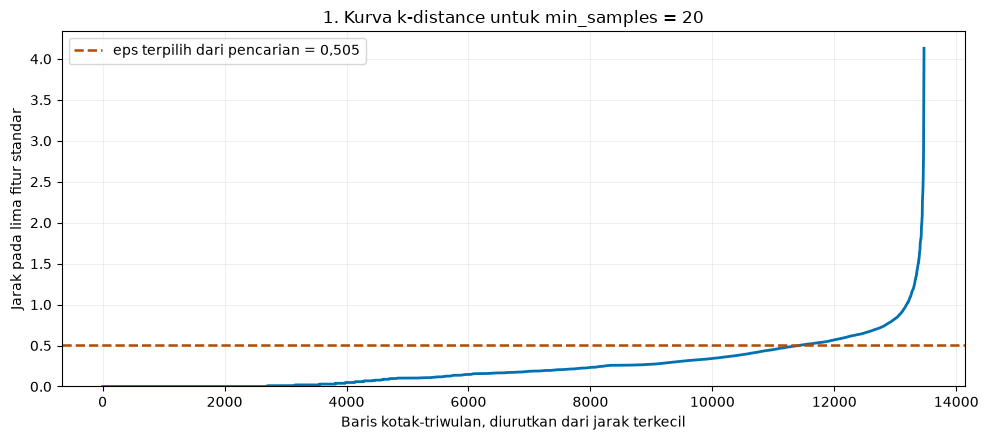

**Bacanya:** bagian kurva yang rendah menunjukkan baris dengan pola yang lebih dekat ke tetangganya.
Ketika kurva menanjak, baris-baris tersebut lebih jauh dari tetangganya.

Garis oranye menunjukkan **eps 0,505 yang dipilih dari pencarian parameter**.
Dalam penelitian ini, kandidat eps berasal dari beberapa kuantil jarak, kemudian diperiksa skor dan ukuran kelompoknya.
Garis ini bukan hasil deteksi titik siku otomatis. Angka jarak bukan kilometer.
Perhitungan tetangga mengikuti min_samples DBSCAN, termasuk baris itu sendiri.


In [7]:
with threadpool_limits(limits=2):
    neighbor_distances = NearestNeighbors(n_neighbors=int(dbscan_metadata["min_samples"]), n_jobs=1).fit(evaluation_X).kneighbors(evaluation_X)[0][:, -1]
sorted_distances = np.sort(neighbor_distances)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(np.arange(1, len(sorted_distances) + 1), sorted_distances, color="#0072B2", linewidth=2)
ax.axhline(dbscan_metadata["eps"], color="#B44A00", linestyle="--", linewidth=1.8,
           label=f"eps terpilih dari pencarian = {angka(dbscan_metadata['eps'], 3)}")
ax.set(title=f"1. Kurva k-distance untuk min_samples = {dbscan_metadata['min_samples']}",
       xlabel="Baris kotak-triwulan, diurutkan dari jarak terkecil", ylabel="Jarak pada lima fitur standar")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left")
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/dbscan_simple_k_distance.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Bacanya:** bagian kurva yang rendah menunjukkan baris dengan pola yang lebih dekat ke tetangganya.
Ketika kurva menanjak, baris-baris tersebut lebih jauh dari tetangganya.

Garis oranye menunjukkan **eps {angka(dbscan_metadata['eps'], 3)} yang dipilih dari pencarian parameter**.
Dalam penelitian ini, kandidat eps berasal dari beberapa kuantil jarak, kemudian diperiksa skor dan ukuran kelompoknya.
Garis ini bukan hasil deteksi titik siku otomatis. Angka jarak bukan kilometer.
Perhitungan tetangga mengikuti min_samples DBSCAN, termasuk baris itu sendiri.
"""))


<a id="s8"></a>
## 8. Langkah 2: bandingkan eps dengan grafik skor

Grafik garis ini menampilkan kandidat eps pada min_samples terpilih. Kiri: Silhouette lebih tinggi lebih baik. Kanan: Davies-Bouldin lebih rendah lebih baik. Bintang oranye menandai pilihan model.

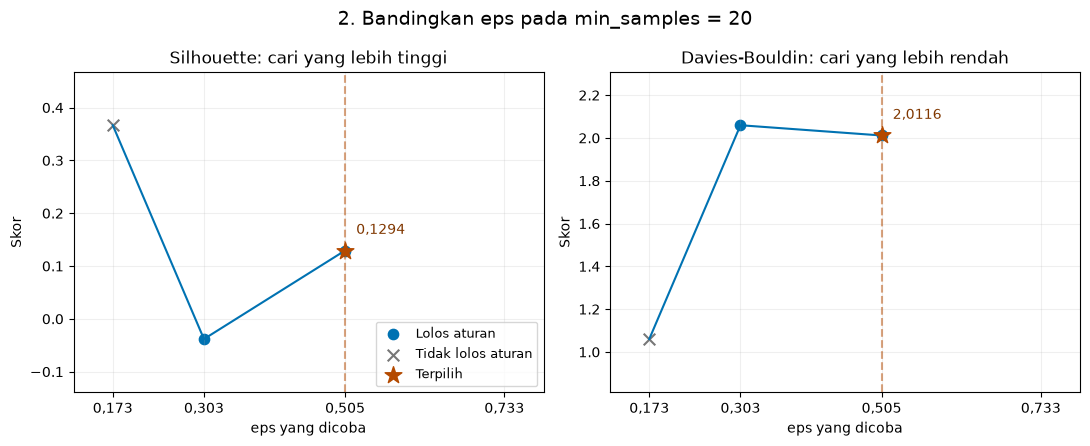

**Bacanya:** sumbu bawah adalah eps yang dicoba. Bintang oranye adalah pilihan model.
Grafik kiri mencari skor lebih tinggi; grafik kanan mencari skor lebih rendah.

Grafik ini memperlihatkan **4 kandidat dengan min_samples 20**, diambil dari seluruh 12 percobaan.
Pilihan akhirnya tetap memakai seluruh pencarian, bukan hanya titik-titik ini.
Tanda silang abu-abu berarti tidak memenuhi aturan penelitian walaupun skornya dapat terlihat baik.
Kandidat yang hanya menghasilkan satu kelompok tidak memiliki skor Silhouette/DBI, sehingga tidak digambar sebagai titik skor.

Di antara kandidat yang lolos, dipilih rata-rata Silhouette tertinggi; jika sama, noise lebih kecil didahulukan.
Seluruh percobaan dan alasan penyaringannya dapat dibuka pada bagian 10.


In [8]:
simple_candidates = search.loc[search["min_samples"].eq(dbscan_metadata["min_samples"])].sort_values("eps")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, metric, title in zip(axes, ["silhouette", "davies_bouldin"],
                            ["Silhouette: cari yang lebih tinggi", "Davies-Bouldin: cari yang lebih rendah"]):
    ax.plot(simple_candidates["eps"], simple_candidates[metric], color="#0072B2", linewidth=1.5)
    valid = simple_candidates[metric].notna()
    accepted = simple_candidates["accepted"] & valid
    rejected = ~simple_candidates["accepted"] & valid
    ax.scatter(simple_candidates.loc[accepted, "eps"], simple_candidates.loc[accepted, metric], color="#0072B2", s=55, label="Lolos aturan")
    ax.scatter(simple_candidates.loc[rejected, "eps"], simple_candidates.loc[rejected, metric], color="#777777", marker="x", s=70, label="Tidak lolos aturan")
    ax.scatter(dbscan_metadata["eps"], selected_result[metric], color="#B44A00", s=160, marker="*", zorder=4, label="Terpilih")
    ax.annotate(angka(selected_result[metric]), (dbscan_metadata["eps"], selected_result[metric]), xytext=(8, 12), textcoords="offset points", color="#803700")
    ax.axvline(dbscan_metadata["eps"], color="#B44A00", linestyle="--", alpha=.5)
    ax.set(title=title, xlabel="eps yang dicoba", ylabel="Skor")
    ax.set_xticks(simple_candidates["eps"], [angka(value, 3) for value in simple_candidates["eps"]])
    ax.margins(x=.15, y=.25)
    eps_span = simple_candidates["eps"].max() - simple_candidates["eps"].min()
    ax.set_xlim(simple_candidates["eps"].min() - .1 * eps_span, simple_candidates["eps"].max() + .1 * eps_span)
    ax.grid(alpha=.2)
axes[0].legend(loc="lower right", fontsize=9)
fig.suptitle(f"2. Bandingkan eps pada min_samples = {dbscan_metadata['min_samples']}", fontsize=14)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/dbscan_simple_eps_scores.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Bacanya:** sumbu bawah adalah eps yang dicoba. Bintang oranye adalah pilihan model.
Grafik kiri mencari skor lebih tinggi; grafik kanan mencari skor lebih rendah.

Grafik ini memperlihatkan **{len(simple_candidates)} kandidat dengan min_samples {dbscan_metadata['min_samples']}**, diambil dari seluruh {len(search)} percobaan.
Pilihan akhirnya tetap memakai seluruh pencarian, bukan hanya titik-titik ini.
Tanda silang abu-abu berarti tidak memenuhi aturan penelitian walaupun skornya dapat terlihat baik.
Kandidat yang hanya menghasilkan satu kelompok tidak memiliki skor Silhouette/DBI, sehingga tidak digambar sebagai titik skor.

Di antara kandidat yang lolos, dipilih rata-rata Silhouette tertinggi; jika sama, noise lebih kecil didahulukan.
Seluruh percobaan dan alasan penyaringannya dapat dibuka pada bagian 10.
"""))


<a id="s9"></a>
## 9. Langkah 3: baca hasil kelompok dan noise

Setelah memilih parameter, lihat berapa kelompok terbentuk dan berapa baris tidak tergabung. Ini hasil model, bukan kategori risiko.

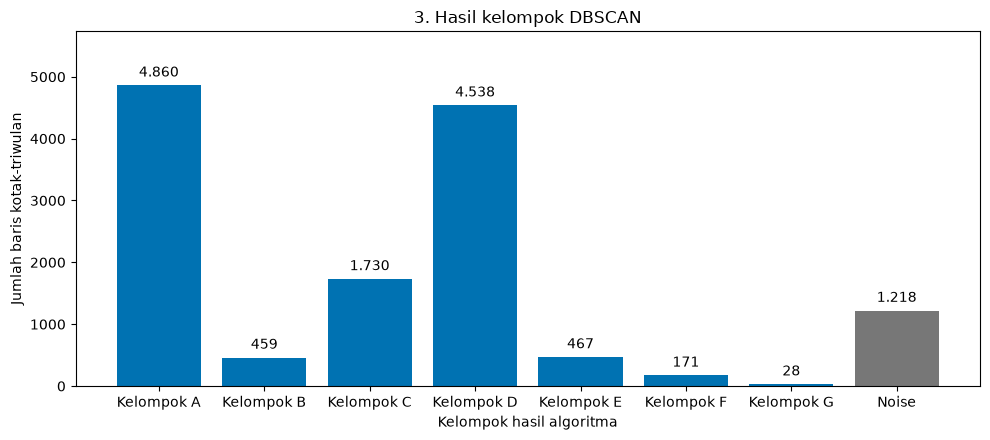

**Bacanya:** batang lebih tinggi berarti kelompok memiliki lebih banyak anggota.
Noise ditampilkan abu-abu dan bukan kelompok tambahan.

| Hasil utama | Nilai |
| --- | ---: |
| eps terpilih | 0,505 |
| min_samples | 20 |
| Kelompok terbentuk | 7 |
| Baris masuk kelompok | 12.253 |
| Noise | 1.218 (9,04%) |
| Silhouette seleksi, seperti grafik bagian 8 | 0,1294 |
| Davies-Bouldin | 2,0116 |

**Kesimpulan:** pada parameter tersebut terbentuk 7 kelompok.
Pemisahannya masih lemah menurut Silhouette yang dekat nol, sehingga hasil dipakai sebagai gambaran eksploratif.
Skor ini bukan akurasi dan warna kelompok bukan tingkat bahaya.


In [9]:
unique_labels, counts = np.unique(dbscan_model.labels_, return_counts=True)
ordered = sorted(zip(unique_labels, counts), key=lambda item: (item[0] < 0, item[0]))
names = ["Noise" if label < 0 else f"Kelompok {chr(65 + int(label))}" for label, _ in ordered]
values = [count for _, count in ordered]
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(names, values, color=["#777777" if label < 0 else "#0072B2" for label, _ in ordered])
ax.bar_label(bars, labels=[jumlah(value) for value in values], padding=4)
ax.set_ylim(0, max(values) * 1.18)
ax.set(title="3. Hasil kelompok DBSCAN", xlabel="Kelompok hasil algoritma", ylabel="Jumlah baris kotak-triwulan")
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/dbscan_simple_group_sizes.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown(f"""**Bacanya:** batang lebih tinggi berarti kelompok memiliki lebih banyak anggota.
Noise ditampilkan abu-abu dan bukan kelompok tambahan.

| Hasil utama | Nilai |
| --- | ---: |
| eps terpilih | {angka(dbscan_metadata['eps'], 3)} |
| min_samples | {dbscan_metadata['min_samples']} |
| Kelompok terbentuk | {jumlah(final_metrics['n_clusters'])} |
| Baris masuk kelompok | {jumlah(final_metrics['n_assigned'])} |
| Noise | {jumlah(noise_rows)} ({angka(final_metrics['noise_fraction'] * 100, 2)}%) |
| Silhouette seleksi, seperti grafik bagian 8 | {angka(selected_result['silhouette'])} |
| Davies-Bouldin | {angka(selected_result['davies_bouldin'])} |

**Kesimpulan:** pada parameter tersebut terbentuk {jumlah(final_metrics['n_clusters'])} kelompok.
Pemisahannya masih lemah menurut Silhouette yang dekat nol, sehingga hasil dipakai sebagai gambaran eksploratif.
Skor ini bukan akurasi dan warna kelompok bukan tingkat bahaya.
"""))
if dbscan_metadata["diagnostic_only"]:
    display(Markdown("**Status diagnostik:** tidak ada kandidat lolos seluruh aturan. Hasil belum memenuhi kriteria penelitian."))


<a id="s10"></a>
## 10. Lampiran: seluruh percobaan dan rincian skor

Bagian ini untuk pemeriksaan lebih lanjut. Tabel 12 percobaan dapat dibuka dengan mengeklik judul tabel di bawah. Alur utama cukup dibaca pada bagian 7-9.

In [10]:
from IPython.display import HTML

def alasan_kandidat(row):
    reasons = []
    if row["n_clusters"] < 2:
        reasons.append("Kurang dari 2 kelompok")
    if row["n_clusters"] > cfg["dbscan_max_clusters"]:
        reasons.append("Terlalu banyak kelompok")
    if row["smallest_cluster_size"] < cfg["dbscan_min_cluster_size"]:
        reasons.append("Kelompok terkecil terlalu sedikit anggota")
    if row["noise_fraction"] > cfg["dbscan_max_noise_fraction"]:
        reasons.append("Noise melewati batas")
    if row["largest_cluster_fraction_assigned"] > cfg["dbscan_max_largest_cluster_fraction"]:
        reasons.append("Satu kelompok terlalu dominan")
    if not np.isfinite(row["silhouette"]):
        reasons.append("Skor tidak terdefinisi")
    return "; ".join(reasons) if reasons else "Lolos aturan"

audit = search[["eps", "min_samples", "n_clusters", "smallest_cluster_size", "noise_fraction", "silhouette", "davies_bouldin"]].copy()
audit["noise_fraction"] *= 100
audit["Status"] = np.where(selected_mask, "TERPILIH", np.where(search["accepted"], "Lolos", "Tidak lolos"))
audit["Alasan"] = search.apply(alasan_kandidat, axis=1)
audit = audit.rename(columns={"n_clusters": "Kelompok", "smallest_cluster_size": "Anggota terkecil", "noise_fraction": "Noise (%)", "silhouette": "Silhouette seleksi", "davies_bouldin": "DBI"})
display(HTML('<details><summary>Buka tabel seluruh percobaan dan alasannya</summary>' + audit.round(4).to_html(index=False, escape=True) + '</details>'))
display(Markdown(f"""**Catatan metode:** aturan penyaringan adalah 2 sampai {cfg['dbscan_max_clusters']} kelompok,
kelompok terkecil minimal {cfg['dbscan_min_cluster_size']} baris, noise maksimal {angka(cfg['dbscan_max_noise_fraction'] * 100, 0)}%,
dominasi kelompok terbesar maksimal {angka(cfg['dbscan_max_largest_cluster_fraction'] * 100, 0)}% dari anggota yang ditugaskan.
Ini pilihan rancangan penelitian; pengaruhnya diperiksa di notebook 08.

Silhouette seleksi **{angka(selected_result['silhouette'])}** adalah rata-rata tiga sampel seed {cfg['silhouette_seeds']}.
Silhouette evaluasi dengan satu sampel seed 42 adalah **{angka(final_metrics['silhouette'])}**, sama dengan notebook 06.
Setiap sampel maksimal {jumlah(cfg['silhouette_sample_size'])} baris; DBI memakai seluruh anggota kelompok.
Noise dikeluarkan dari kedua skor. Perbedaan skor sampel tidak mengubah model.
"""))
display(FileLink(str(ROOT / "models/dbscan/parameter_search.csv"), result_html_prefix="CSV seluruh percobaan: "))
display(FileLink(str(ROOT / "reports/figures/dbscan_silhouette_samples.png"), result_html_prefix="Grafik Silhouette per anggota (detail tambahan): "))


eps,min_samples,Kelompok,Anggota terkecil,Noise (%),Silhouette seleksi,DBI,Status,Alasan
0.0538,5,251,4,46.6706,0.6045,0.4916,Tidak lolos,Terlalu banyak kelompok; Kelompok terkecil terlalu sedikit anggota
0.1602,5,146,3,26.1599,0.2344,1.1374,Tidak lolos,Terlalu banyak kelompok; Kelompok terkecil terlalu sedikit anggota
0.2916,5,51,3,11.5507,-0.1119,1.6099,Tidak lolos,Terlalu banyak kelompok; Kelompok terkecil terlalu sedikit anggota
0.4912,5,14,4,3.0362,-0.0403,1.5833,Tidak lolos,Kelompok terkecil terlalu sedikit anggota
0.1044,10,95,5,45.4755,0.4976,0.9728,Tidak lolos,Terlalu banyak kelompok; Kelompok terkecil terlalu sedikit anggota
0.2242,10,68,10,24.8905,0.2196,1.6639,Tidak lolos,Terlalu banyak kelompok; Kelompok terkecil terlalu sedikit anggota
0.3879,10,19,11,10.3853,-0.0367,2.2547,Tidak lolos,Kelompok terkecil terlalu sedikit anggota
0.6100,10,2,479,2.5388,-0.0769,4.6543,Tidak lolos,Satu kelompok terlalu dominan
0.1728,20,42,12,43.1816,0.3666,1.0604,Tidak lolos,Terlalu banyak kelompok; Kelompok terkecil terlalu sedikit anggota
0.3032,20,14,20,24.0368,-0.0382,2.0595,Lolos,Lolos aturan


**Catatan metode:** aturan penyaringan adalah 2 sampai 20 kelompok,
kelompok terkecil minimal 20 baris, noise maksimal 50%,
dominasi kelompok terbesar maksimal 95% dari anggota yang ditugaskan.
Ini pilihan rancangan penelitian; pengaruhnya diperiksa di notebook 08.

Silhouette seleksi **0,1294** adalah rata-rata tiga sampel seed [42, 7, 21].
Silhouette evaluasi dengan satu sampel seed 42 adalah **0,1261**, sama dengan notebook 06.
Setiap sampel maksimal 2.000 baris; DBI memakai seluruh anggota kelompok.
Noise dikeluarkan dari kedua skor. Perbedaan skor sampel tidak mengubah model.


C:\Users\yudhi\Documents\machine-learning\models\dbscan\parameter_search.csv

C:\Users\yudhi\Documents\machine-learning\reports\figures\dbscan_silhouette_samples.png

<a id="s11"></a>
## 11. Ringkasan alur DBSCAN

Hubungkan pemilihan parameter dengan hasil yang akan dibandingkan pada notebook evaluasi model.

In [11]:
display(Markdown(f"""### Alur yang bisa diikuti

**Lihat jarak antarpola → bandingkan kandidat eps → periksa kelompok yang terbentuk.**

K-Means memakai grafik elbow untuk membantu memilih jumlah kelompok k.
DBSCAN memakai eps dan min_samples; jumlah kelompok muncul setelah model dijalankan.
Kurva k-distance membantu memahami kandidat eps, sedangkan pemilihan dalam penelitian ini memakai skor dan aturan penyaringan.
Kita tidak menetapkan tujuh kelompok sejak awal.

Hasil pada data ini: **{jumlah(final_metrics['n_clusters'])} kelompok dan {angka(final_metrics['noise_fraction'] * 100, 2)}% noise**.
Ciri setiap kelompok dibaca pada tabel bagian 6.
Perbandingan dengan K-Means dilanjutkan di [notebook 06](../06_model_evaluation/06_model_evaluation.ipynb).
"""))


### Alur yang bisa diikuti

**Lihat jarak antarpola → bandingkan kandidat eps → periksa kelompok yang terbentuk.**

K-Means memakai grafik elbow untuk membantu memilih jumlah kelompok k.
DBSCAN memakai eps dan min_samples; jumlah kelompok muncul setelah model dijalankan.
Kurva k-distance membantu memahami kandidat eps, sedangkan pemilihan dalam penelitian ini memakai skor dan aturan penyaringan.
Kita tidak menetapkan tujuh kelompok sejak awal.

Hasil pada data ini: **7 kelompok dan 9,04% noise**.
Ciri setiap kelompok dibaca pada tabel bagian 6.
Perbandingan dengan K-Means dilanjutkan di [notebook 06](../06_model_evaluation/06_model_evaluation.ipynb).


## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.